# Predicting Product Demand in E-Commerce Using Data Analysis and Machine Learning
## Phase 1 – Exploratory Data Analysis (EDA)

**Team Members**
- Noor Btoosh – 202410877
- Diaa Al Ayyoub – 202320065
- Aya Aburajab – 202320127
- Sara Al Qaneer – 202320243

## 1. Introduction and Data Dictionary
This notebook explores the **Online Retail II** dataset to prepare for a model that predicts **weekly product demand** (quantity sold per product per week) in later phases.

| Column | Type | Meaning |
|---|---|---|
| Invoice | text | Invoice number (starts with **C** if the order was cancelled) |
| StockCode | text | Product code |
| Description | text | Product name |
| Quantity | integer | Units per line (negative for cancellations) |
| InvoiceDate | datetime | Date and time of the transaction |
| Price | float | Unit price in GBP |
| Customer ID | numeric | Customer identifier (missing for some rows) |
| Country | text | Customer's country |

## 2. Environment Setup
- **Python version:** 3.11.9
- **Virtual environment:** `.venv` (created with `venv`)
- **IDE / notebook:** Visual Studio Code with Jupyter
- **Packages:** pandas, numpy, matplotlib, seaborn, openpyxl, jupyter (full list with versions in `requirements.txt`)

Commands used (run in the project folder):
```
python -m venv .venv
.venv\Scripts\activate
pip install pandas numpy matplotlib seaborn openpyxl jupyter ipykernel
pip freeze > requirements.txt
```
- **Git repository:** https://github.com/dia005/PDS_OnlineRetail

## 3. Import Libraries

In [1]:
import sys
import functools
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

sns.set_theme(style="whitegrid")

Python: 3.11.9
Pandas: 3.1.1
NumPy: 2.4.6


## 4. Helper Functions
These functions use type hints, error handling and a decorator (`log_rows`) that prints how many rows each cleaning step keeps.

In [2]:
REQUIRED_COLUMNS = ["Invoice", "StockCode", "Description", "Quantity",
                    "InvoiceDate", "Price", "Customer ID", "Country"]


def log_rows(func):
    """Decorator: print the number of rows before and after a cleaning step."""
    @functools.wraps(func)
    def wrapper(data: pd.DataFrame) -> pd.DataFrame:
        result = func(data)
        print(f"{func.__name__}: {len(data):,} -> {len(result):,} rows")
        return result
    return wrapper


def load_retail_data(path: Path) -> pd.DataFrame:
    """Read every sheet of the Excel file and stack them into one DataFrame."""
    try:
        sheets = pd.read_excel(path, sheet_name=None)
    except FileNotFoundError:
        raise FileNotFoundError(f"Place online_retail_II.xlsx in the data folder: {path}")
    return pd.concat(sheets.values(), ignore_index=True)


def validate_columns(data: pd.DataFrame, required: list[str]) -> None:
    """Raise an error if an expected column is missing."""
    missing = [col for col in required if col not in data.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")


@log_rows
def remove_duplicates(data: pd.DataFrame) -> pd.DataFrame:
    return data.drop_duplicates().copy()


@log_rows
def keep_valid_sales(data: pd.DataFrame) -> pd.DataFrame:
    """Keep real sales: not cancelled, positive quantity and positive price."""
    valid = (~data["IsCancelled"]) & (data["Quantity"] > 0) & (data["Price"] > 0)
    return data.loc[valid].copy()

## 5. Load the Dataset

In [3]:
df = load_retail_data(Path("../data/online_retail_II.xlsx"))
validate_columns(df, REQUIRED_COLUMNS)
print("Dataset shape:", df.shape)

Dataset shape: (1067371, 8)


## 6. Inspect the Dataset

In [4]:
display(df.head())
display(df.tail())

print("Rows and columns:", df.shape)
df.info()

display(df.describe(include="all").T)

# Dictionary comprehension: percentage of missing values per column
missing_pct = {col: round(float(df[col].isna().mean() * 100), 1) for col in df.columns}
print("Missing values (%):", missing_pct)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


Rows and columns: (1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values (%): {'Invoice': 0.0, 'StockCode': 0.0, 'Description': 0.4, 'Quantity': 0.0, 'InvoiceDate': 0.0, 'Price': 0.0, 'Customer ID': 22.8, 'Country': 0.0}


**Observations:** the dataset has 1,067,371 rows and 8 columns spread over two yearly sheets. Only two columns have gaps: `Customer ID` (243,007 rows, 22.8%) and `Description` (4,382 rows, 0.4%). Dates, quantities, prices and countries are complete, so product-level demand can be analysed from every row.

## 7. Handle Missing Values

In [5]:
print("Missing values before handling:")
display(df.isna().sum().to_frame("Missing Before"))

df_clean = df.copy()
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

print("Missing values after handling:")
display(df_clean.isna().sum().to_frame("Missing After"))

Missing values before handling:


,Missing Before
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


Missing values after handling:


,Missing After
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


**Decisions:**
- `Description` (0.4% missing) is filled with "Unknown" so that no transaction is lost.
- `Customer ID` (22.8% missing) is kept. Demand is counted per product and does not need the customer, so these rows stay in the demand analysis. They are excluded only from customer-level calculations (customer summary and Pareto curve).

## 8. Handle Duplicate Rows

In [6]:
print("Duplicate rows before removal:", df_clean.duplicated().sum())
df_clean = remove_duplicates(df_clean)
print("Duplicate rows after removal:", df_clean.duplicated().sum())

Duplicate rows before removal: 34335
remove_duplicates: 1,067,371 -> 1,033,036 rows
Duplicate rows after removal: 0


**Observations:** 34,335 exact duplicate rows (3.2%) were removed. Of these, 12,133 are repeated inside the sheets and the rest appear in both sheets because the two sheets overlap on 1–9 December 2010. Keeping them would have double-counted demand.

## 9. Handle Data Types

In [7]:
df_clean["Invoice"] = df_clean["Invoice"].astype(str)
df_clean["StockCode"] = df_clean["StockCode"].astype(str)
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["Customer ID"] = df_clean["Customer ID"].astype("Int64")

print(df_clean.dtypes)

Invoice                   str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                   str
dtype: object


`Invoice` and `StockCode` mix numbers and text (for example `C489449`, `85123A`), so both are stored as text. `Customer ID` becomes an integer that allows missing values.

## 10. Prepare Sales and Demand Data

In [8]:
df_clean["IsCancelled"] = df_clean["Invoice"].str.startswith("C")

# Sales data: real sales only (used for revenue, countries, prices)
sales_df = keep_valid_sales(df_clean)
sales_df["TotalSales"] = sales_df["Quantity"] * sales_df["Price"]

# Demand data: also keeps cancellations (negative quantity) so returned orders cancel out
net_df = df_clean.loc[df_clean["Price"] > 0].copy()

returns = df_clean.loc[df_clean["IsCancelled"]]
print(f"Cancelled lines: {len(returns):,} ({-returns['Quantity'].sum():,} units returned)")

example = df_clean.loc[df_clean["StockCode"] == "23843"]
print("Product 23843 - units sold:", example.loc[example["Quantity"] > 0, "Quantity"].sum(),
      "| net units after cancellations:", example["Quantity"].sum())

keep_valid_sales: 1,033,036 -> 1,007,913 rows
Cancelled lines: 19,104 (476,819 units returned)
Product 23843 - units sold: 80995 | net units after cancellations: 0


**Why two datasets?** Cancelled invoices (starting with C) carry negative quantities. Simply dropping them hides returns: product 23843 shows 80,995 units sold, but that single order was cancelled minutes later, so its net demand is 0. We therefore use `sales_df` (real sales, for revenue, countries and prices) and `net_df` (sales plus cancellations, for demand).

## 11. Filtering

In [9]:
high_quantity_sales = sales_df.loc[sales_df["Quantity"] > 10]
uk_sales = sales_df.loc[sales_df["Country"] == "United Kingdom"]

print("Sales lines with quantity greater than 10:", len(high_quantity_sales))
print("United Kingdom sales lines:", len(uk_sales))
display(high_quantity_sales.head())

Sales lines with quantity greater than 10: 255021
United Kingdom sales lines: 926038


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0


## 12. GroupBy

In [10]:
# Net units per product
product_demand = (
    net_df.groupby("StockCode", as_index=False)
    .agg(NetQuantity=("Quantity", "sum"))
    .sort_values("NetQuantity", ascending=False)
)

# Sales per country
country_sales = (
    sales_df.groupby("Country", as_index=False)
    .agg(TotalSales=("TotalSales", "sum"))
    .sort_values("TotalSales", ascending=False)
)

# Orders and spending per customer (only rows with a Customer ID)
customer_summary = (
    sales_df.dropna(subset=["Customer ID"])
    .groupby("Customer ID", as_index=False)
    .agg(Orders=("Invoice", "nunique"), TotalSpent=("TotalSales", "sum"))
)

# Weekly demand per product - the target planned for the prediction model
weekly_demand = (
    net_df.assign(Week=net_df["InvoiceDate"].dt.to_period("W").dt.start_time)
    .groupby(["StockCode", "Week"], as_index=False)
    .agg(WeeklyQuantity=("Quantity", "sum"))
)

display(product_demand.head(10))
display(country_sales.head(10))
display(customer_summary.describe())
print("Weekly demand table:", weekly_demand.shape)
display(weekly_demand["WeeklyQuantity"].describe())

,StockCode,NetQuantity
3555,84077,104435
4286,85099B,95544
617,21212,93774
4314,85123A,90566
1441,22197,87695
4004,84879,79571
114,17003,69629
1253,21977,55842
4140,84991,53678
17,15036,43343


,Country,TotalSales
40,United Kingdom,1.741020e+07
11,EIRE,6.587673e+05
26,Netherlands,5.540381e+05
15,Germany,4.250197e+05
14,France,3.504561e+05
0,Australia,1.692835e+05
34,Spain,1.083325e+05
36,Switzerland,1.006856e+05
35,Sweden,9.186982e+04
10,Denmark,6.858069e+04


,Customer ID,Orders,TotalSpent
count,5878.0,5878.000000,5878.000000
mean,15315.313542,6.289384,2955.904095
std,1715.572666,13.009406,14440.852688
min,12346.0,1.000000,2.950000
25%,13833.25,1.000000,342.280000
50%,15314.5,3.000000,867.740000
75%,16797.75,7.000000,2248.305000
max,18287.0,398.000000,580987.040000


Weekly demand table: (199935, 3)


count    199935.000000
mean         53.659084
std         178.658320
min       -8429.000000
25%           3.000000
50%          13.000000
75%          48.000000
max       19165.000000
Name: WeeklyQuantity, dtype: float64

**Observations:** the weekly demand table has 199,935 product-week rows. The median product sells 13 units a week, but the maximum is 19,165, so weekly demand is highly skewed. The minimum is negative (-8,429) because some returns are recorded in a later week than the original sale (2,387 product-weeks, 1.2%), which must be handled before modelling.

## 13. Merge

In [11]:
product_info = (
    sales_df[["StockCode", "Description"]]
    .assign(Description=lambda d: d["Description"].str.strip())
    .drop_duplicates(subset="StockCode")
)

merged_data = pd.merge(product_demand, product_info, on="StockCode", how="left")
display(merged_data.head(10))

,StockCode,NetQuantity,Description
0,84077,104435,WORLD WAR 2 GLIDERS ASSTD DESIGNS
1,85099B,95544,JUMBO BAG RED WHITE SPOTTY
2,21212,93774,PACK OF 72 RETRO SPOT CAKE CASES
3,85123A,90566,WHITE HANGING HEART T-LIGHT HOLDER
4,22197,87695,"POPCORN HOLDER , SMALL"
5,84879,79571,ASSORTED COLOUR BIRD ORNAMENT
6,17003,69629,BROCADE RING PURSE
7,21977,55842,PACK OF 60 PINK PAISLEY CAKE CASES
8,84991,53678,60 TEATIME FAIRY CAKE CASES
9,15036,43343,ASSORTED COLOURS SILK FAN


## 14. Pivot Table

In [12]:
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month

monthly_pivot = pd.pivot_table(
    sales_df, values="TotalSales", index="Month", columns="Year",
    aggfunc="sum", fill_value=0
)
display(monthly_pivot.round(0))

Year,2009,2010,2011
Month,,,
1,0.0,651155.0,689812.0
2,0.0,551505.0,522546.0
3,0.0,830915.0,716215.0
4,0.0,678875.0,536968.0
5,0.0,657706.0,769297.0
6,0.0,749537.0,760547.0
7,0.0,648810.0,718076.0
8,0.0,695252.0,757841.0
9,0.0,921697.0,1056435.0


**Observations:** sales rise every autumn. September to November are the strongest months in both 2010 and 2011 (November: £1.46M in 2010 and £1.50M in 2011), while January to August stay between about £520k and £830k. December 2011 looks lower only because the data ends on 9 December.

## 15. Descriptive Statistics

In [13]:
display(sales_df[["Quantity", "Price", "TotalSales"]].describe())

,Quantity,Price,TotalSales
count,1.007913e+06,1.007913e+06,1.007913e+06
mean,1.111718e+01,4.074252e+00,2.031550e+01
std,1.284700e+02,5.043045e+01,2.057158e+02
min,1.000000e+00,1.000000e-03,1.000000e-03
25%,1.000000e+00,1.250000e+00,4.130000e+00
50%,4.000000e+00,2.100000e+00,1.008000e+01
75%,1.200000e+01,4.130000e+00,1.770000e+01
max,8.099500e+04,2.511109e+04,1.684696e+05


## 16. NumPy Calculations

In [14]:
quantities = sales_df["Quantity"].to_numpy()
prices = sales_df["Price"].to_numpy()

# 1) Outliers with the IQR rule
q1, q3 = np.percentile(quantities, [25, 75])
upper_limit = q3 + 1.5 * (q3 - q1)
outlier_share = np.mean(quantities > upper_limit) * 100
print(f"IQR upper limit: {upper_limit:.0f} units | lines above it: {outlier_share:.1f}%")

# 2) Log transform to reduce skew
log_quantities = np.log1p(quantities)
print(f"Mean/median ratio - raw: {np.mean(quantities) / np.median(quantities):.2f}, "
      f"log: {np.mean(log_quantities) / np.median(log_quantities):.2f}")

# 3) Correlation between price and quantity (log scale)
corr = np.corrcoef(np.log1p(prices), log_quantities)[0, 1]
print(f"Correlation of log price and log quantity: {corr:.2f}")

# 4) Customer concentration (Pareto): cumulative share of spending
spend = np.sort(customer_summary["TotalSpent"].to_numpy())[::-1]
cum_share = np.cumsum(spend) / spend.sum()
top20_share = cum_share[int(0.2 * len(spend)) - 1]
print(f"Top 20% of customers generate {top20_share:.1%} of sales")

IQR upper limit: 28 units | lines above it: 5.3%
Mean/median ratio - raw: 2.78, log: 1.07
Correlation of log price and log quantity: -0.42
Top 20% of customers generate 77.2% of sales


**Observations:** quantities are very skewed. Only 5.3% of lines are above the IQR limit of 28 units, yet the mean is 2.8 times the median; after a log transform the ratio drops to 1.07, so a log scale suits modelling. Price and quantity are moderately negatively correlated (-0.42): cheaper items sell in larger quantities. The top 20% of customers generate 77.2% of sales.

## 17. Visualisation 1 – Top 10 Products by Net Quantity Sold

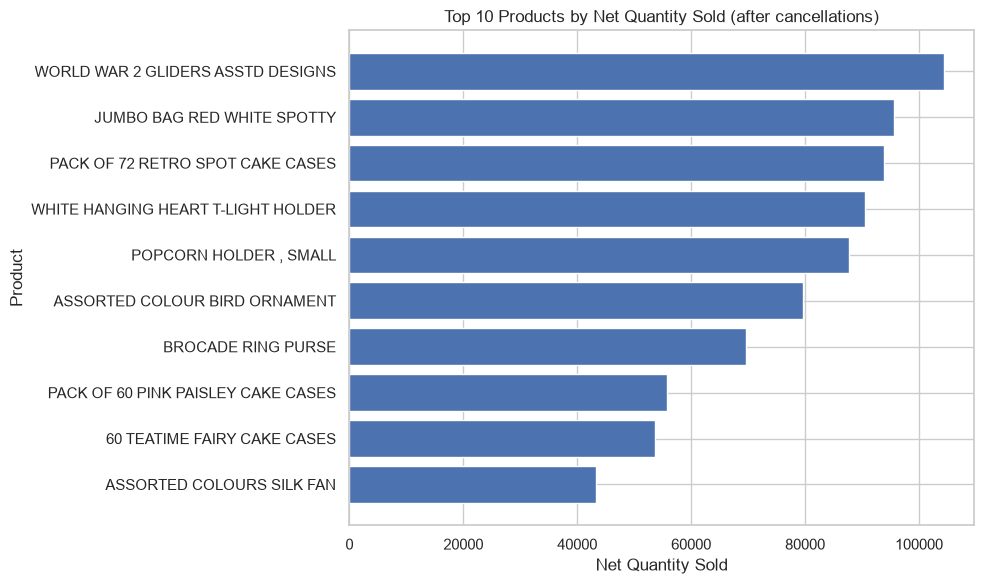

In [15]:
top_products = merged_data.head(10).iloc[::-1]
labels = top_products["Description"].str[:36]

plt.figure(figsize=(10, 6))
plt.barh(labels, top_products["NetQuantity"])
plt.title("Top 10 Products by Net Quantity Sold (after cancellations)")
plt.xlabel("Net Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Insight – top products:** WORLD WAR 2 GLIDERS ASSTD DESIGNS leads with 104,435 net units, followed by JUMBO BAG RED WHITE SPOTTY (95,544) and PACK OF 72 RETRO SPOT CAKE CASES (93,774). Three of the ten products are cake cases and most are low-priced, so volume comes from cheap items bought in bulk. Netting out cancellations matters: without it, two products whose huge orders were cancelled (23843 and 23166) appeared in the top 10.

## 18. Visualisation 2 – Top 10 Countries by Sales (excluding the UK)

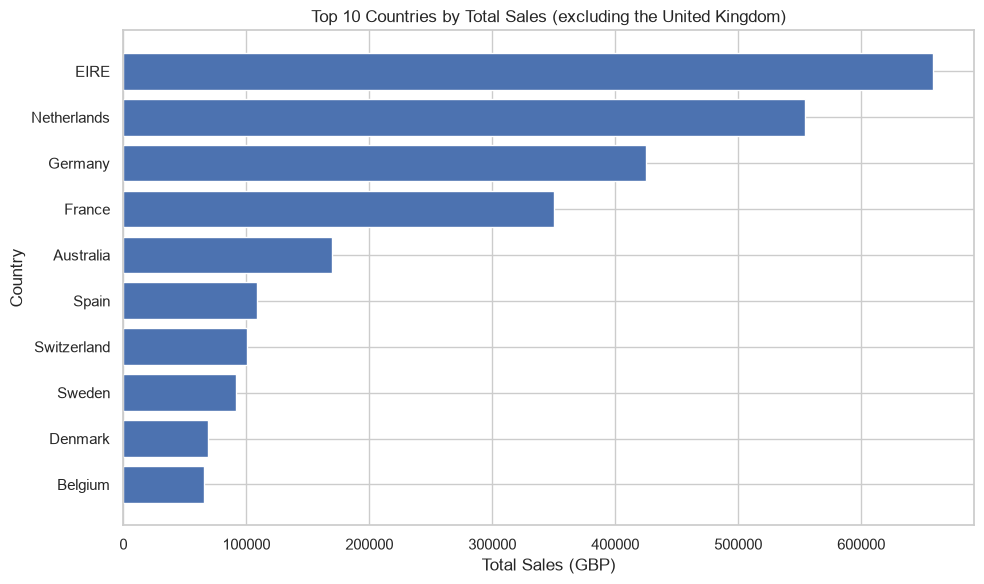

United Kingdom share of total sales: 85.0%


In [16]:
uk_share = country_sales.loc[country_sales["Country"] == "United Kingdom", "TotalSales"].iloc[0] / country_sales["TotalSales"].sum()
top_countries = country_sales.loc[country_sales["Country"] != "United Kingdom"].head(10).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top_countries["Country"], top_countries["TotalSales"])
plt.title("Top 10 Countries by Total Sales (excluding the United Kingdom)")
plt.xlabel("Total Sales (GBP)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
print(f"United Kingdom share of total sales: {uk_share:.1%}")

**Insight – countries:** The United Kingdom makes up 85.0% of total sales, so it is left out of the chart to make the other markets readable. EIRE (£659k), the Netherlands (£554k), Germany (£425k) and France (£350k) lead the rest. International sales come from a few nearby European markets, so country is a useful but secondary feature for a demand model.

## 19. Visualisation 3 – Monthly Sales Trend

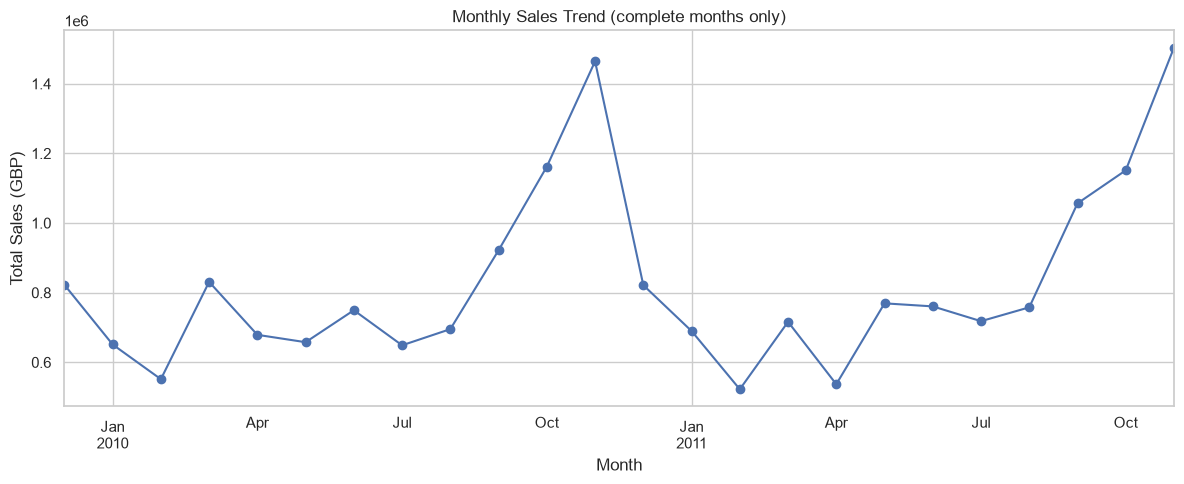

Peak month: November 2011 with 1,503,867 GBP (monthly average: 826,602 GBP)


In [17]:
monthly_sales = sales_df.set_index("InvoiceDate")["TotalSales"].resample("MS").sum()
monthly_sales = monthly_sales.iloc[:-1]   # December 2011 is incomplete (data ends on 9 Dec)

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend (complete months only)")
plt.xlabel("Month")
plt.ylabel("Total Sales (GBP)")
plt.tight_layout()
plt.show()

peak_month = monthly_sales.idxmax()
print(f"Peak month: {peak_month:%B %Y} with {monthly_sales.max():,.0f} GBP "
      f"(monthly average: {monthly_sales.mean():,.0f} GBP)")

**Insight – monthly trend:** Sales follow a clear seasonal pattern: they rise from September and peak in November 2011 at £1.50M, 82% above the monthly average of £0.83M. The same peak appears in November 2010 (£1.46M). A demand model should include month or week of the year to capture this Christmas-driven seasonality.

## 20. Visualisation 4 – Distribution of Quantity per Sales Line

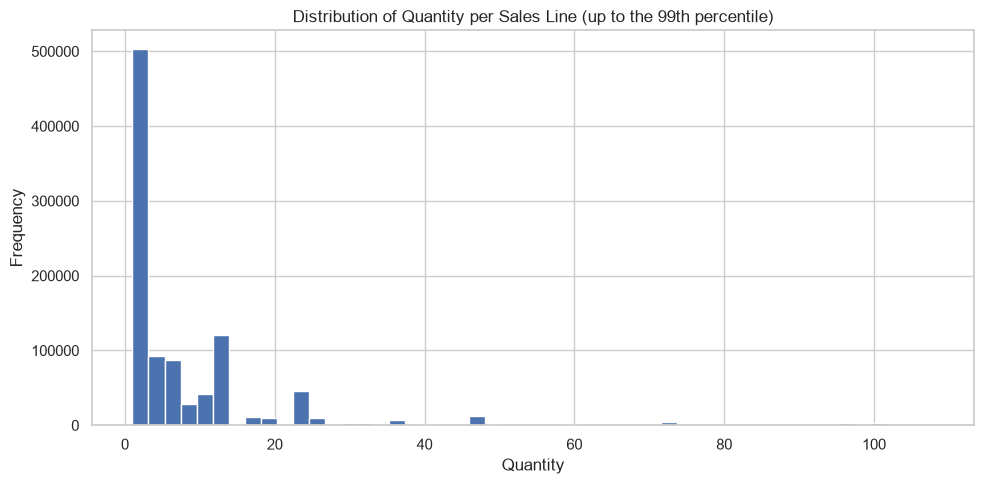

Mean = 11.1, median = 4, 99th percentile = 108


In [18]:
quantity_limit = sales_df["Quantity"].quantile(0.99)
quantity_to_plot = sales_df.loc[sales_df["Quantity"] <= quantity_limit, "Quantity"]

plt.figure(figsize=(10, 5))
plt.hist(quantity_to_plot, bins=50)
plt.title("Distribution of Quantity per Sales Line (up to the 99th percentile)")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(f"Mean = {sales_df['Quantity'].mean():.1f}, median = {sales_df['Quantity'].median():.0f}, "
      f"99th percentile = {quantity_limit:.0f}")

**Insight – quantity distribution:** Most sales lines are small: the median is 4 units and 75% of lines have 12 units or fewer, while the mean is 11.1 and the 99th percentile is 108. The long right tail (up to 80,995 units in one line) comes from bulk orders. Quantity should be log-transformed, or outliers treated, before modelling.

## 21. Visualisation 5 – Monthly Net Demand for the Top 5 Products

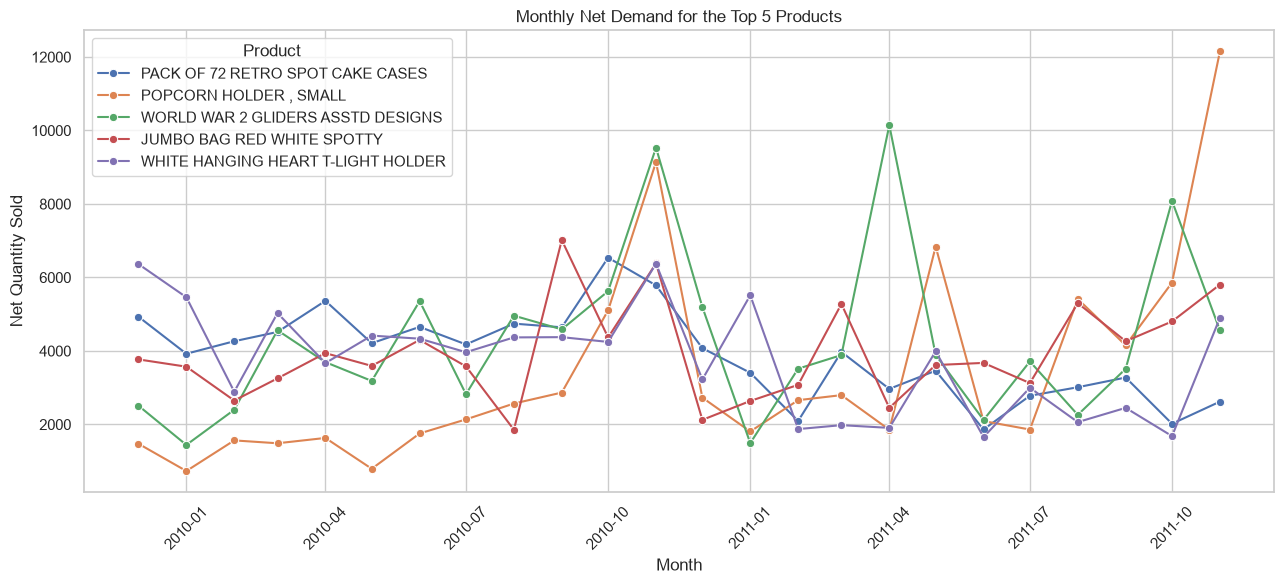

In [19]:
desc_map = dict(zip(product_info["StockCode"], product_info["Description"]))
top_5_codes = product_demand.head(5)["StockCode"]

monthly_demand = (
    net_df.loc[net_df["StockCode"].isin(top_5_codes) & (net_df["InvoiceDate"] < "2011-12-01")]
    .assign(Month=lambda d: d["InvoiceDate"].dt.to_period("M").dt.to_timestamp())
    .groupby(["Month", "StockCode"], as_index=False)
    .agg(Quantity=("Quantity", "sum"))
)
monthly_demand["Product"] = monthly_demand["StockCode"].map(desc_map).str[:36]

plt.figure(figsize=(13, 6))
sns.lineplot(data=monthly_demand, x="Month", y="Quantity", hue="Product", marker="o")
plt.title("Monthly Net Demand for the Top 5 Products")
plt.xlabel("Month")
plt.ylabel("Net Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight – top-5 product demand:** Demand for the top products is irregular rather than steady. Each product peaks in a different month (for example 21212 in October 2010, 85123A in November 2010, 84077 in April 2011 and 22197 in November 2011), and its peak month is typically 1.6 to 5.2 times its median month (22197 sold 12,151 units in November 2011 against a median month of about 2,350). Product-level demand is spiky, so lagged demand and seasonality features should help the model.

## 22. Visualisation 6 – Customer Concentration (Pareto Curve)

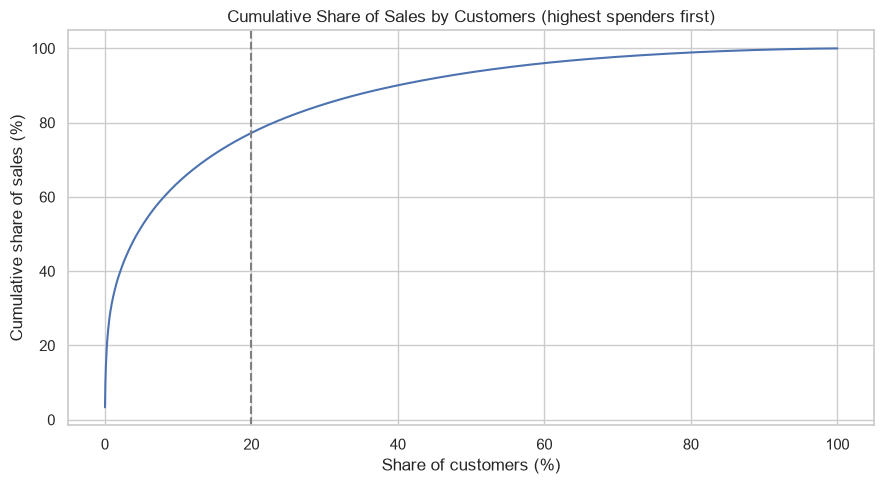

In [20]:
share_of_customers = np.arange(1, len(cum_share) + 1) / len(cum_share) * 100

plt.figure(figsize=(9, 5))
plt.plot(share_of_customers, cum_share * 100)
plt.axvline(20, color="grey", linestyle="--")
plt.title("Cumulative Share of Sales by Customers (highest spenders first)")
plt.xlabel("Share of customers (%)")
plt.ylabel("Cumulative share of sales (%)")
plt.tight_layout()
plt.show()

**Insight – customer concentration:** Sales are concentrated: the top 20% of customers generate 77.2% of sales, close to the 80/20 rule. A small group of high-value customers therefore drives revenue, which makes total demand sensitive to a few large buyers.

## 23. Advanced Python – Generator and Lambda
A generator yields one month of data at a time, and a lambda function groups prices into two categories.

In [21]:
def month_chunks(data: pd.DataFrame):
    """Generator: yield (month, rows of that month) one month at a time."""
    for period, chunk in data.groupby(data["InvoiceDate"].dt.to_period("M")):
        yield period, chunk


orders_per_month = {str(period): chunk["Invoice"].nunique()
                    for period, chunk in month_chunks(sales_df)}
busiest = max(orders_per_month, key=orders_per_month.get)
print(f"Busiest month by number of orders: {busiest} ({orders_per_month[busiest]:,} orders)")

sales_df["PriceCategory"] = sales_df["Price"].apply(lambda p: "Low (< 5 GBP)" if p < 5 else "High (>= 5 GBP)")
display(sales_df.groupby("PriceCategory").agg(Lines=("Quantity", "size"), Units=("Quantity", "sum")))

Busiest month by number of orders: 2011-11 (2,769 orders)


,Lines,Units
PriceCategory,,
High (>= 5 GBP),175384,556578
Low (< 5 GBP),832529,10648570


**Observations:** the number of orders also peaks in November 2011 (2,769 orders), matching the sales peak. Low-priced lines (under 5 GBP) make up 82.6% of sales lines and 95.0% of units sold, so demand volume is driven by cheap products.

**Where advanced Python is used in this notebook:** list and dictionary comprehensions (sections 6 and 23), a decorator `log_rows` (sections 4, 8, 10), a generator `month_chunks` (section 23), lambda functions (sections 13 and 23), type hints on all functions (section 4) and error handling in `load_retail_data` and `validate_columns` (sections 4 and 5).

## 24. Conclusions

**Key findings**
- After removing 34,335 duplicates and cancelled or invalid lines, 1,007,913 valid sales lines remain from the original 1,067,371 rows.
- Demand is **seasonal** (September–November peak, November 2011 sales 82% above the monthly average), **skewed** (median 4 units per line, with bulk orders up to 80,995), and driven by **cheap products** (95.0% of units) and **a few customers** (top 20% generate 77.2% of sales).
- The United Kingdom accounts for 85.0% of sales; EIRE, the Netherlands, Germany and France are the main other markets.
- Cancellations must be netted out: otherwise cancelled bulk orders (such as product 23843) wrongly appear as top sellers.

**Link to the prediction task (Phase 3):** the target is weekly quantity sold per product (199,935 product-week rows). Useful features are month or week of the year, lagged demand, price and country, with a log transform for the skew.

**Limitations**
- 22.8% of rows have no Customer ID, so customer-level results cover only identified customers.
- 1.2% of product-weeks have negative demand because returns fall in a later week than the sale.
- A few non-product codes (for example POST for postage) are still included.
- December 2011 is incomplete (data ends on 9 December), so it is excluded from the trend charts.

**Phase 2:** the dataset will be enriched with UK public-holiday data to test whether holidays explain part of the weekly demand.